In [1]:
# Cell 1 - Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pickle, json, os, warnings
warnings.filterwarnings('ignore')
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# Cell 2 - Configuration
SEQ_LENGTH    = 30
BATCH_SIZE    = 64
EPOCHS        = 100
LEARNING_RATE = 0.001
MODEL_NAME    = 'gru_model'

In [3]:
# Cell 3 - Load Data
full_df = pd.read_csv('../data/processed/full_engineered.csv', parse_dates=['Date'])
with open('../data/processed/top_features.pkl', 'rb') as f:
    feature_cols = pickle.load(f)
with open('../data/processed/scaler_y.pkl', 'rb') as f:
    scaler_y = pickle.load(f)
target_col = 'Units_Sold_scaled'
print(f"Data loaded. Shape: {full_df.shape} | Features: {len(feature_cols)}")

Data loaded. Shape: (89750, 56) | Features: 30


In [4]:
# Cell 4 - Create Sequences & Splits
def create_sequences(data, feature_cols, target_col, seq_length=30):
    X_seqs, y_seqs = [], []
    for sku in sorted(data['SKU_ID'].unique()):
        sku_data = data[data['SKU_ID'] == sku].sort_values('Date')
        X = sku_data[feature_cols].fillna(0).values
        y = sku_data[target_col].values
        for i in range(seq_length, len(X)):
            X_seqs.append(X[i - seq_length:i])
            y_seqs.append(y[i])
    return np.array(X_seqs, dtype=np.float32), np.array(y_seqs, dtype=np.float32)

dates = np.sort(full_df['Date'].unique())
n = len(dates)
train_cutoff = dates[int(n * 0.70)]
val_cutoff   = dates[int(n * 0.85)]
train_df = full_df[full_df['Date'] <= train_cutoff]
val_df   = full_df[(full_df['Date'] > train_cutoff) & (full_df['Date'] <= val_cutoff)]
test_df  = full_df[full_df['Date'] > val_cutoff]

X_train, y_train = create_sequences(train_df, feature_cols, target_col, SEQ_LENGTH)
X_val,   y_val   = create_sequences(val_df,   feature_cols, target_col, SEQ_LENGTH)
X_test,  y_test  = create_sequences(test_df,  feature_cols, target_col, SEQ_LENGTH)
print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

X_train: (61500, 30, 30) | X_val: (12000, 30, 30) | X_test: (11750, 30, 30)


In [5]:
# Cell 5 - Build GRU Model Architecture
def build_gru_model(seq_length, n_features, units=[128, 64, 32], dropout_rate=0.3):
    """3-layer Stacked GRU — faster convergence than LSTM, fewer parameters."""
    model = Sequential([
        Input(shape=(seq_length, n_features)),
        GRU(units[0], return_sequences=True, name='gru_1'),
        BatchNormalization(),
        Dropout(dropout_rate),
        GRU(units[1], return_sequences=True, name='gru_2'),
        BatchNormalization(),
        Dropout(dropout_rate),
        GRU(units[2], return_sequences=False, name='gru_3'),
        BatchNormalization(),
        Dropout(dropout_rate / 2),
        Dense(32, activation='relu', name='dense_1'),
        Dense(16, activation='relu', name='dense_2'),
        Dense(1, name='output')
    ], name='GRU_Model')
    return model

model = build_gru_model(SEQ_LENGTH, len(feature_cols))
model.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss='huber', metrics=['mae'])
model.summary()

Model: "GRU_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                          │ (None, 30, 128)             │          61,440 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 30, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 30, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_2 (GRU)                          │ (None, 30, 64)              │          37,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 30, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_3 (GRU)                          │ (None, 32)                  │           9,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,593 (432.00 KB)

 Trainable params: 110,145 (430.25 KB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
# Cell 6 - Train GRU Model
os.makedirs('../models', exist_ok=True)
callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=1),
    ModelCheckpoint(f'../models/{MODEL_NAME}.keras', monitor='val_loss', save_best_only=True, verbose=1)
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
print(f"Training complete. Best val_loss: {min(history.history['val_loss']):.6f}")

Epoch 1/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 0.0132 - mae: 0.1249
Epoch 1: val_loss improved from None to 0.00701, saving model to ../models/gru_model.keras

Epoch 1: finished saving model to ../models/gru_model.keras
961/961 ━━━━━━━━━━━━━━━━━━━━ 76s 70ms/step - loss: 0.0132 - mae: 0.1249 - val_loss: 0.0070 - val_mae: 0.0955 - learning_rate: 0.0010
Epoch 2/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0090 - mae: 0.1066
Epoch 2: val_loss did not improve from 0.00701
961/961 ━━━━━━━━━━━━━━━━━━━━ 52s 54ms/step - loss: 0.0090 - mae: 0.1066 - val_loss: 0.0070 - val_mae: 0.0958 - learning_rate: 0.0010
Epoch 3/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0087 - mae: 0.1048
Epoch 3: val_loss did not improve from 0.00701
961/961 ━━━━━━━━━━━━━━━━━━━━ 58s 60ms/step - loss: 0.0087 - mae: 0.1048 - val_loss: 0.0071 - val_mae: 0.0960 - learning_rate: 0.0010
Epoch 4/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.0085 - mae: 0.1036
Epoch 4: val_loss impro

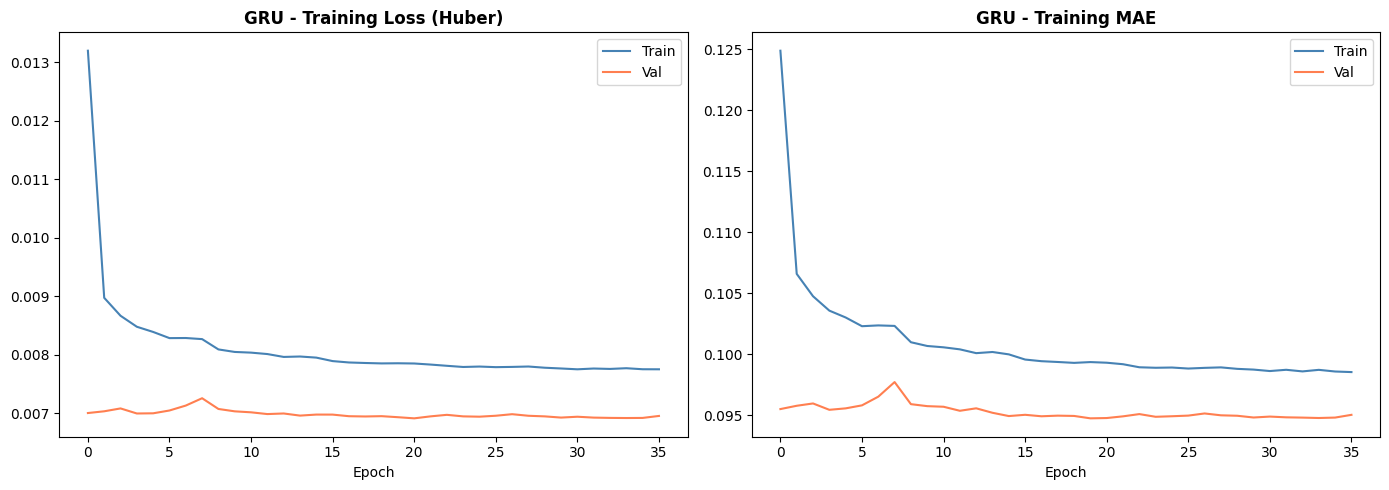

In [7]:
# Cell 7 - Training Curves
os.makedirs('../outputs/plots', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'],     label='Train', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val',   color='coral')
axes[0].set_title('GRU - Training Loss (Huber)', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history.history['mae'],     label='Train', color='steelblue')
axes[1].plot(history.history['val_mae'], label='Val',   color='coral')
axes[1].set_title('GRU - Training MAE', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig('../outputs/plots/05_gru_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Cell 8 - Evaluate GRU
y_pred_scaled = model.predict(X_test, verbose=0).flatten()
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
y_true = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = r2_score(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
print(f"GRU TEST METRICS -> RMSE: {rmse:.4f} | MAE: {mae:.4f} | R²: {r2:.4f} | MAPE: {mape:.2f}%")

GRU TEST METRICS -> RMSE: 7.3016 | MAE: 5.8842 | R²: -0.6160 | MAPE: 38.79%


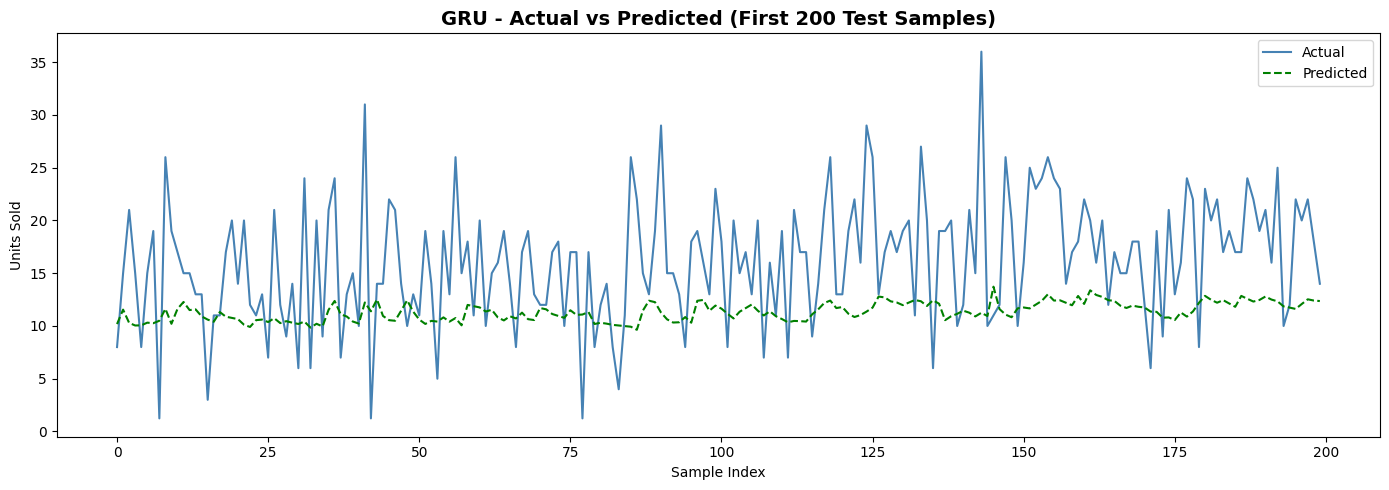

In [9]:
# Cell 9 - Actual vs Predicted
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_true[:200], label='Actual',    color='steelblue', linewidth=1.5)
ax.plot(y_pred[:200], label='Predicted', color='green',     linewidth=1.5, linestyle='--')
ax.set_title('GRU - Actual vs Predicted (First 200 Test Samples)', fontsize=14, fontweight='bold')
ax.set_xlabel('Sample Index'); ax.set_ylabel('Units Sold'); ax.legend()
plt.tight_layout()
plt.savefig('../outputs/plots/05_gru_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Cell 10 - Save GRU Results
os.makedirs('../outputs/reports', exist_ok=True)
gru_results = {'RMSE': float(rmse), 'MAE': float(mae), 'R2': float(r2), 'MAPE': float(mape)}
with open('../outputs/reports/gru_metrics.json', 'w') as f:
    json.dump(gru_results, f, indent=2)
np.save('../data/processed/gru_predictions.npy', y_pred)
print("\n✅ GRU Model Complete!")
print("Model saved to: models/gru_model.keras")


✅ GRU Model Complete!
Model saved to: models/gru_model.keras
